# Wettervergleich: Berlin 2025

Dieses Notebook vergleicht historische Tageswerte für Berlin im Kalenderjahr 2025. Der Open-Meteo-Ort wird über die Geocoding-API gesucht; verglichen wird mit den Tagesbeobachtungen der DWD-Station Berlin-Tempelhof (Stations-ID 00433).

Die Suche nach „Tempelhof“ in Deutschland ergibt den Ort **Tempelhof, Land Berlin** (Open-Meteo-Geocoding-ID 2823538; 52.46667° N, 13.40000° E). Diese Koordinaten liegen nahe der DWD-Station. Open-Meteo liefert Archiv-/Reanalysedaten für einen Rasterpunkt, der DWD Stationsmessungen. Die Quellen sind deshalb vergleichbar, aber nicht identisch. Für beide Abrufe brauchst du eine Internetverbindung; API-Schlüssel sind für dieses Beispiel nicht erforderlich.

## 1. Vorbereitung

Für Tabellen und Diagramme verwenden wir `pandas` und `matplotlib`. Führe die Installationszelle einmal aus, falls die Pakete in deiner Python-Umgebung noch fehlen. Danach kannst du die übrigen Zellen von oben nach unten ausführen.

In [32]:
%pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [33]:
import json
from io import BytesIO
from urllib.parse import urlencode
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd

# Open-Meteo-Ort Tempelhof in Berlin über die Geocoding-API suchen
geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"
geocoding_parameter = {
    "name": "Tempelhof",
    "count": 10,
    "language": "de",
    "format": "json",
    "countryCode": "DE",
}
geocoding_anfrage = f"{geocoding_url}?{urlencode(geocoding_parameter)}"
with urlopen(geocoding_anfrage, timeout=30) as antwort:
    geocoding_json = json.load(antwort)

standort = next(
    (
        ort for ort in geocoding_json.get("results", [])
        if ort.get("name") == "Tempelhof" and ort.get("admin1") == "Land Berlin"
    ),
    None,
)
if standort is None:
    raise LookupError("Open-Meteo hat Tempelhof im Land Berlin nicht gefunden.")

breitengrad = standort["latitude"]
laengengrad = standort["longitude"]
start_datum = "2025-01-01"
end_datum = "2025-12-31"

print(f"Open-Meteo-Ort: {standort['name']}, {standort['admin1']}")
print(f"Geocoding-ID: {standort['id']}")
print(f"Koordinaten: {breitengrad}, {laengengrad}")

Open-Meteo-Ort: Tempelhof, Land Berlin
Geocoding-ID: 2823538
Koordinaten: 52.46667, 13.4


## 2. Open-Meteo-Daten laden

Die Zelle fragt die Tagesmittel-, Minimal- und Maximaltemperatur sowie die tägliche Niederschlagssumme für die zuvor gefundene Tempelhof-Koordinate ab. Die URL wird mit `urlencode` aus den Parametern zusammengesetzt.

In [34]:
api_url = "https://archive-api.open-meteo.com/v1/archive"
parameter = {
    "latitude": breitengrad,
    "longitude": laengengrad,
    "start_date": start_datum,
    "end_date": end_datum,
    "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum",
    "timezone": "Europe/Berlin",
}
anfrage_url = f"{api_url}?{urlencode(parameter)}"

try:
    with urlopen(anfrage_url, timeout=30) as antwort:
        wetter_json = json.load(antwort)
except Exception as fehler:
    raise RuntimeError("Wetterdaten konnten nicht geladen werden. Prüfe Internetverbindung und Zeitraum.") from fehler

tagesdaten = wetter_json["daily"]
wetter = pd.DataFrame({
    "datum": pd.to_datetime(tagesdaten["time"]),
    "temperatur_mittel_c": tagesdaten["temperature_2m_mean"],
    "temperatur_max_c": tagesdaten["temperature_2m_max"],
    "temperatur_min_c": tagesdaten["temperature_2m_min"],
    "niederschlag_mm": tagesdaten["precipitation_sum"],
})

print(f"Geladene Tage: {len(wetter)}")
print(f"Zeitzone: {wetter_json['timezone']}")

Geladene Tage: 365
Zeitzone: Europe/Berlin


## 3. DWD-Daten laden

Als Referenz verwenden wir die DWD-Tageswerte der Station **Berlin-Tempelhof (Stations-ID 00433)** aus dem [DWD-Archiv für Tageswerte](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/). Die DWD-CSV-Spalten `TMK`, `TXK`, `TNK` und `RSK` stehen für Tagesmittel, Tagesmaximum, Tagesminimum und Niederschlag. Der DWD kennzeichnet fehlende Messwerte mit `-999`; diese werden in fehlende Werte umgewandelt.

In [35]:
dwd_zip_url = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/tageswerte_KL_00433_19480101_20251231_hist.zip"

with urlopen(dwd_zip_url, timeout=60) as antwort:
    dwd_zip_bytes = BytesIO(antwort.read())

with ZipFile(dwd_zip_bytes) as archiv:
    produkt_name = next(
        name for name in archiv.namelist()
        if name.startswith("produkt_klima_tag_")
    )
    with archiv.open(produkt_name) as datei:
        dwd_roh = pd.read_csv(
            datei,
            sep=";",
            encoding="latin-1",
            skipinitialspace=True,
        )

dwd_roh.columns = dwd_roh.columns.str.strip()
dwd = dwd_roh[["MESS_DATUM", "TMK", "TXK", "TNK", "RSK"]].copy()
dwd["datum"] = pd.to_datetime(
    dwd.pop("MESS_DATUM").astype(str),
    format="%Y%m%d",
)
dwd = dwd.loc[dwd["datum"].between(start_datum, end_datum)].copy()
dwd = dwd.rename(columns={
    "TMK": "temperatur_mittel_dwd_c",
    "TXK": "temperatur_max_dwd_c",
    "TNK": "temperatur_min_dwd_c",
    "RSK": "niederschlag_dwd_mm",
})

messwerte = [
    "temperatur_mittel_dwd_c",
    "temperatur_max_dwd_c",
    "temperatur_min_dwd_c",
    "niederschlag_dwd_mm",
]
for spalte in messwerte:
    dwd[spalte] = pd.to_numeric(dwd[spalte], errors="coerce").replace(-999, float("nan"))

vergleich = wetter.merge(dwd, on="datum", how="inner")
print(f"DWD-Tage im Zeitraum: {len(dwd)}")
print(f"Gemeinsame Vergleichstage: {len(vergleich)}")

DWD-Tage im Zeitraum: 365
Gemeinsame Vergleichstage: 365


## 4. Daten ansehen und Quellen vergleichen

Die Tabelle zeigt die zusammengeführten Tageswerte. Für Temperatur und Niederschlag berechnen wir nur mit Tagen, an denen beide Quellen einen Wert haben: Jahresmittel bzw. Jahressumme, mittlere Abweichung (Open-Meteo minus DWD), mittlere absolute Abweichung (MAE), RMSE und Korrelation. MAE und RMSE beschreiben die Größe der täglichen Unterschiede; die Korrelation zeigt, ob beide Reihen zeitlich ähnlich verlaufen. Sie bedeutet nicht, dass die Werte identisch sind.

In [36]:
display(vergleich.head())

temperatur_vergleich = vergleich.dropna(
    subset=["temperatur_mittel_c", "temperatur_mittel_dwd_c"]
)
niederschlag_vergleich = vergleich.dropna(
    subset=["niederschlag_mm", "niederschlag_dwd_mm"]
)
temperatur_differenz = (
    temperatur_vergleich["temperatur_mittel_c"]
    - temperatur_vergleich["temperatur_mittel_dwd_c"]
)
niederschlag_differenz = (
    niederschlag_vergleich["niederschlag_mm"]
    - niederschlag_vergleich["niederschlag_dwd_mm"]
)
waermster_tag = dwd.loc[dwd["temperatur_max_dwd_c"].idxmax()]
kaeltester_tag = dwd.loc[dwd["temperatur_min_dwd_c"].idxmin()]
tag_mit_groesster_abweichung = temperatur_vergleich.loc[
    temperatur_differenz.abs().idxmax()
]

print(f"Gemeinsame Temperaturtage: {len(temperatur_vergleich)}")
print(f"Open-Meteo Jahresmittel: {temperatur_vergleich['temperatur_mittel_c'].mean():.1f} °C")
print(f"DWD Jahresmittel: {temperatur_vergleich['temperatur_mittel_dwd_c'].mean():.1f} °C")
print(f"Mittlere Temperaturabweichung (Open-Meteo minus DWD): {temperatur_differenz.mean():+.2f} °C")
print(f"Temperatur-MAE: {temperatur_differenz.abs().mean():.2f} °C")
print(f"Temperatur-RMSE: {(temperatur_differenz.pow(2).mean()) ** 0.5:.2f} °C")
print(f"Temperatur-Korrelation: {temperatur_vergleich['temperatur_mittel_c'].corr(temperatur_vergleich['temperatur_mittel_dwd_c']):.3f}")
print(f"Größte Tagesabweichung: {tag_mit_groesster_abweichung['datum'].date()} ({temperatur_differenz.loc[tag_mit_groesster_abweichung.name]:+.1f} °C)")
print(f"Niederschlag Open-Meteo: {niederschlag_vergleich['niederschlag_mm'].sum(min_count=1):.1f} mm")
print(f"Niederschlag DWD: {niederschlag_vergleich['niederschlag_dwd_mm'].sum(min_count=1):.1f} mm")
print(f"Niederschlag-MAE pro Tag: {niederschlag_differenz.abs().mean():.2f} mm")
print(f"Niederschlag-Korrelation: {niederschlag_vergleich['niederschlag_mm'].corr(niederschlag_vergleich['niederschlag_dwd_mm']):.3f}")
print(f"Wärmster DWD-Tag: {waermster_tag['datum'].date()} mit {waermster_tag['temperatur_max_dwd_c']:.1f} °C")
print(f"Kältester DWD-Tag: {kaeltester_tag['datum'].date()} mit {kaeltester_tag['temperatur_min_dwd_c']:.1f} °C")

,datum,temperatur_mittel_c,temperatur_max_c,temperatur_min_c,niederschlag_mm,temperatur_mittel_dwd_c,temperatur_max_dwd_c,temperatur_min_dwd_c,niederschlag_dwd_mm
0,2025-01-01,4.8,7.0,0.5,0.1,5.5,8.5,2.0,0.8
1,2025-01-02,4.1,6.9,1.0,3.9,4.6,8.4,2.0,0.2
2,2025-01-03,1.0,2.6,-1.3,4.6,1.4,3.8,-1.0,0.4
3,2025-01-04,-0.9,0.9,-2.3,0.0,0.0,0.6,-0.8,0.0
4,2025-01-05,-1.0,1.8,-2.4,9.4,-0.8,1.2,-2.6,10.9


Gemeinsame Temperaturtage: 365
Open-Meteo Jahresmittel: 10.8 °C
DWD Jahresmittel: 11.1 °C
Mittlere Temperaturabweichung (Open-Meteo minus DWD): -0.30 °C
Temperatur-MAE: 0.59 °C
Temperatur-RMSE: 0.76 °C
Temperatur-Korrelation: 0.996
Größte Tagesabweichung: 2025-02-19 (-2.8 °C)
Niederschlag Open-Meteo: 596.4 mm
Niederschlag DWD: 458.5 mm
Niederschlag-MAE pro Tag: 1.07 mm
Niederschlag-Korrelation: 0.766
Wärmster DWD-Tag: 2025-07-02 mit 37.6 °C
Kältester DWD-Tag: 2025-02-18 mit -11.6 °C


## 5. Beide Quellen im Diagramm vergleichen

Die Linien zeigen die Tagesmitteltemperatur von Open-Meteo und DWD; das farbige Band zeigt beim DWD die Spanne vom Tagesminimum bis zum Tagesmaximum. Die gruppierten Monatsbalken vergleichen den Niederschlag beider Quellen; die genaue Monatssumme steht zusätzlich in der Tabelle. Die y-Achse des Niederschlagsdiagramms skaliert dynamisch bis 15 % über dem größten Monatswert, damit Balken nicht abgeschnitten werden. Unterschiede sind plausibel, da ein Modellrasterpunkt und eine Stationsmessung nicht identisch sind.

,Open-Meteo (mm),DWD Tempelhof (mm)
Jan,81.0,54.9
Feb,23.7,16.0
Mär,13.6,8.7
Apr,19.7,13.7
Mai,23.3,33.8
Jun,60.5,34.6
Jul,158.4,127.4
Aug,39.8,32.6
Sep,53.2,35.1
Okt,60.0,44.8


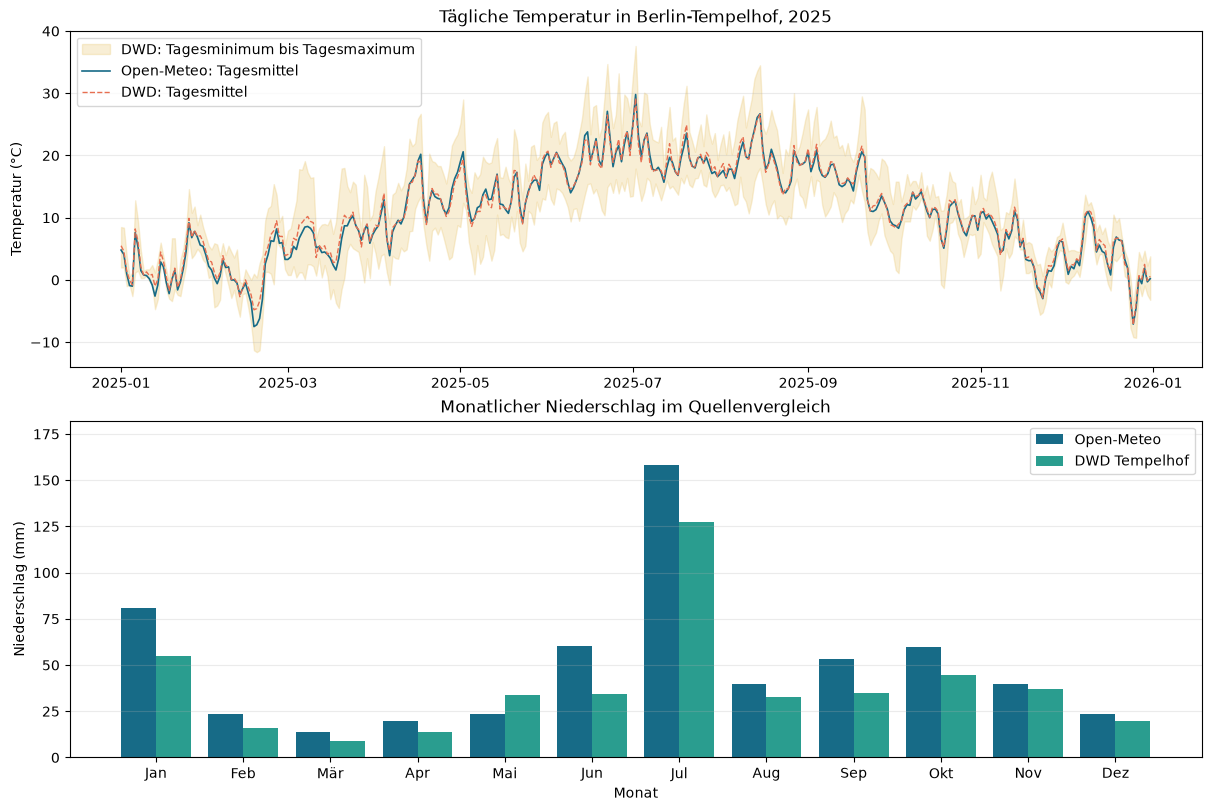

In [38]:
monate = range(1, 13)
monatsdaten = vergleich.assign(monat=vergleich["datum"].dt.month)
niederschlag_openmeteo = (
    monatsdaten.groupby("monat")["niederschlag_mm"]
    .sum(min_count=1)
    .reindex(monate)
)
niederschlag_dwd = (
    monatsdaten.groupby("monat")["niederschlag_dwd_mm"]
    .sum(min_count=1)
    .reindex(monate)
)
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

niederschlag_monatstabelle = pd.DataFrame(
    {
        "Open-Meteo (mm)": niederschlag_openmeteo.to_numpy(),
        "DWD Tempelhof (mm)": niederschlag_dwd.to_numpy(),
    },
    index=monatsnamen,
)
display(niederschlag_monatstabelle.round(1))

fig, achsen = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)

achsen[0].fill_between(
    vergleich["datum"],
    vergleich["temperatur_min_dwd_c"],
    vergleich["temperatur_max_dwd_c"],
    color="#e9c46a",
    alpha=0.28,
    label="DWD: Tagesminimum bis Tagesmaximum",
)
achsen[0].plot(
    vergleich["datum"],
    vergleich["temperatur_mittel_c"],
    color="#176b87",
    linewidth=1.2,
    label="Open-Meteo: Tagesmittel",
)
achsen[0].plot(
    vergleich["datum"],
    vergleich["temperatur_mittel_dwd_c"],
    color="#e76f51",
    linewidth=1.0,
    linestyle="--",
    label="DWD: Tagesmittel",
)
achsen[0].set_title("Tägliche Temperatur in Berlin-Tempelhof, 2025")
achsen[0].set_ylabel("Temperatur (°C)")
achsen[0].legend()
achsen[0].grid(axis="y", alpha=0.25)

achsen[1].bar(
    [monat - 0.2 for monat in monate],
    niederschlag_openmeteo.values,
    width=0.4,
    color="#176b87",
    label="Open-Meteo",
)
achsen[1].bar(
    [monat + 0.2 for monat in monate],
    niederschlag_dwd.values,
    width=0.4,
    color="#2a9d8f",
    label="DWD Tempelhof",
)
max_niederschlag = max(
    niederschlag_openmeteo.max(),
    niederschlag_dwd.max(),
)
achsen[1].set_ylim(0, max_niederschlag * 1.15)
achsen[1].set_xticks(range(1, 13), monatsnamen)
achsen[1].set_title("Monatlicher Niederschlag im Quellenvergleich")
achsen[1].set_ylabel("Niederschlag (mm)")
achsen[1].set_xlabel("Monat")
achsen[1].legend()
achsen[1].grid(axis="y", alpha=0.25)

plt.show()

## 6. Eigene Fragen ausprobieren

- In welchem Monat unterscheiden sich die Niederschlagswerte der Quellen am stärksten?
- An welchen Tagen weichen die Temperaturmittel besonders voneinander ab?
- Wie verändert sich der Vergleich, wenn du Start- und Enddatum auf einen anderen Zeitraum setzt?

Beide Datenquellen werden beim Ausführen neu abgerufen. Das Notebook benötigt deshalb eine Internetverbindung.